# 04 · Network Flow

**Moving product through a network at minimum cost is a linear program.** The
transportation LP ships from sources (plants) to sinks (customers) respecting supply
and demand; its transshipment extension routes through intermediate warehouses with
flow conserved at each. Both have an exact cheapest solution, and the **shadow prices**
on the supply and demand constraints are the marginal value of capacity at each node.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from src.config import SETTINGS
from src.network.transportation import check_conservation, solve_transportation
from src.network.transshipment import solve_transshipment
from src.outputs import save_figure, save_json

plt.rcParams["figure.figsize"] = (7, 4)
rng = np.random.default_rng(SETTINGS.seed)

## A transportation problem

Three plants, six customers. Transport cost per unit is the Euclidean distance; total
supply comfortably covers total demand.

In [2]:
n_plants, n_customers = 3, 6
plant_xy = rng.uniform(0.0, 100.0, (n_plants, 2))
customer_xy = rng.uniform(0.0, 100.0, (n_customers, 2))
demand = rng.uniform(30.0, 70.0, n_customers)
supply = rng.uniform(80.0, 140.0, n_plants)
supply = supply * (demand.sum() / supply.sum()) * 1.3
cost = np.sqrt(((plant_xy[:, None, :] - customer_xy[None, :, :]) ** 2).sum(axis=2))

solution = solve_transportation(supply, demand, cost)
save_json({"supply": supply, "demand": demand, "cost": cost}, "04_transportation_inputs")
save_json(solution, "04_transportation_solution")
print(f"status: {solution.status}   total cost: {solution.total_cost:.1f}")
print(f"flow conservation holds: {check_conservation(solution.flows, supply, demand)}")

status: Optimal   total cost: 12090.8
flow conservation holds: True


## The optimal flows

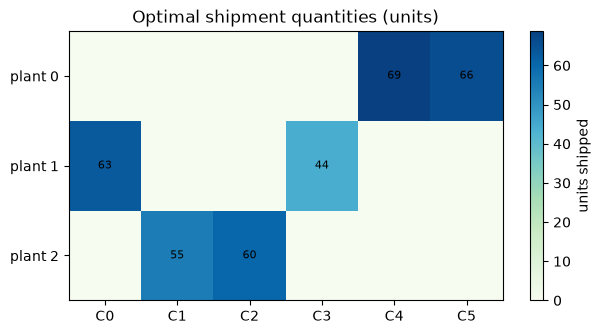

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
im = ax.imshow(solution.flows, cmap="GnBu", aspect="auto")
ax.set_xticks(range(n_customers), [f"C{j}" for j in range(n_customers)])
ax.set_yticks(range(n_plants), [f"plant {i}" for i in range(n_plants)])
for i in range(n_plants):
    for j in range(n_customers):
        value = solution.flows[i, j]
        if value > 1e-6:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Optimal shipment quantities (units)")
fig.colorbar(im, ax=ax, label="units shipped")
save_figure(fig, "04_transportation_flows")
plt.show()

## Shadow prices: the marginal value of capacity

The dual on each demand constraint is what serving one more unit at that customer costs;
the dual on each supply constraint is what one more unit of supply at that plant is
worth.

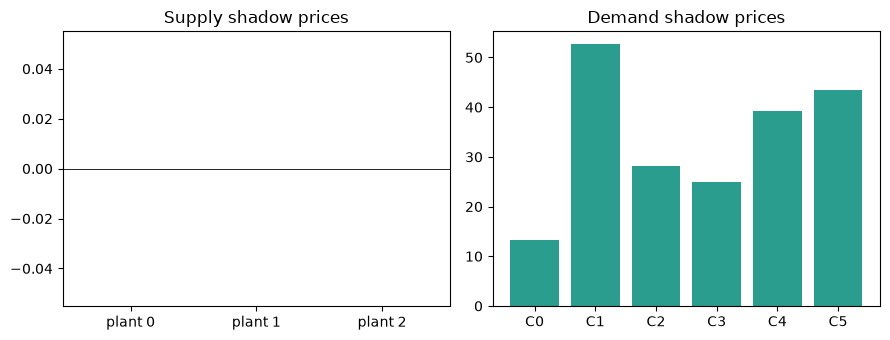

In [4]:
save_json({"supply_prices": solution.supply_prices, "demand_prices": solution.demand_prices},
          "04_shadow_prices")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar([f"plant {i}" for i in range(n_plants)], solution.supply_prices, color="#e76f51")
axes[0].set_title("Supply shadow prices")
axes[0].axhline(0, color="black", linewidth=0.6)
axes[1].bar([f"C{j}" for j in range(n_customers)], solution.demand_prices, color="#2a9d8f")
axes[1].set_title("Demand shadow prices")
axes[1].axhline(0, color="black", linewidth=0.6)
fig.tight_layout()
save_figure(fig, "04_shadow_prices")
plt.show()

## Transshipment: routing through warehouses

Now insert a layer of intermediate warehouses. Flow must be conserved at each warehouse
(what comes in goes out), and we still meet all demand at minimum total cost.

In [5]:
n_sources, n_warehouses, n_cust2 = 2, 3, 6
source_xy = rng.uniform(0.0, 100.0, (n_sources, 2))
warehouse_xy = rng.uniform(0.0, 100.0, (n_warehouses, 2))
cust2_xy = rng.uniform(0.0, 100.0, (n_cust2, 2))
demand2 = rng.uniform(25.0, 55.0, n_cust2)
supply2 = np.array([demand2.sum() * 0.7, demand2.sum() * 0.7])
cost_sw = np.sqrt(((source_xy[:, None, :] - warehouse_xy[None, :, :]) ** 2).sum(axis=2))
cost_wc = np.sqrt(((warehouse_xy[:, None, :] - cust2_xy[None, :, :]) ** 2).sum(axis=2))

ts = solve_transshipment(supply2, demand2, cost_sw, cost_wc)
inflow = ts.source_to_warehouse.sum(axis=0)
outflow = ts.warehouse_to_customer.sum(axis=1)
save_json(ts, "04_transshipment_solution")
print(f"status: {ts.status}   total cost: {ts.total_cost:.1f}")
print(f"warehouse inflow : {np.round(inflow, 1)}")
print(f"warehouse outflow: {np.round(outflow, 1)}")
print(f"conserved at every warehouse: {np.allclose(inflow, outflow, atol=1e-6)}")

status: Optimal   total cost: 15690.8
warehouse inflow : [70.2 94.8 60.2]
warehouse outflow: [70.2 94.8 60.2]
conserved at every warehouse: True


## The routed network

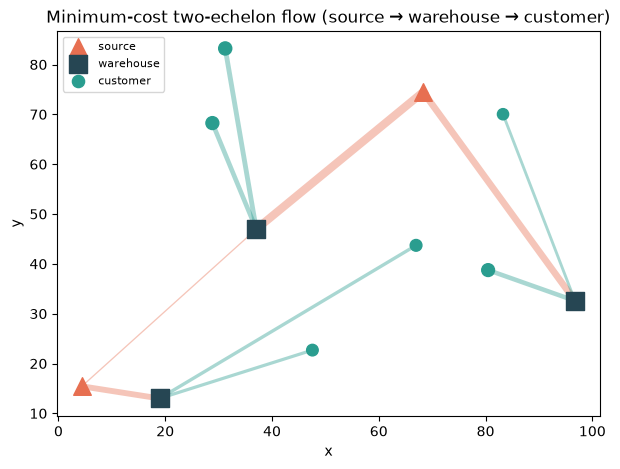

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(source_xy[:, 0], source_xy[:, 1], marker="^", s=160, color="#e76f51", zorder=3, label="source")
ax.scatter(warehouse_xy[:, 0], warehouse_xy[:, 1], marker="s", s=160, color="#264653", zorder=3, label="warehouse")
ax.scatter(cust2_xy[:, 0], cust2_xy[:, 1], s=40 + demand2, color="#2a9d8f", zorder=3, label="customer")
scale = ts.warehouse_to_customer.max()
for s in range(n_sources):
    for w in range(n_warehouses):
        flow = ts.source_to_warehouse[s, w]
        if flow > 1e-6:
            ax.plot([source_xy[s, 0], warehouse_xy[w, 0]], [source_xy[s, 1], warehouse_xy[w, 1]],
                    color="#e76f51", alpha=0.4, linewidth=0.5 + 3 * flow / scale, zorder=1)
for w in range(n_warehouses):
    for c in range(n_cust2):
        flow = ts.warehouse_to_customer[w, c]
        if flow > 1e-6:
            ax.plot([warehouse_xy[w, 0], cust2_xy[c, 0]], [warehouse_xy[w, 1], cust2_xy[c, 1]],
                    color="#2a9d8f", alpha=0.4, linewidth=0.5 + 3 * flow / scale, zorder=1)
ax.set_title("Minimum-cost two-echelon flow (source → warehouse → customer)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "04_transshipment_network")
plt.show()

## Takeaway

The network is a flow problem with an exact cheapest solution. Conservation holds by
construction, the optimal routing falls out of the LP, and the shadow prices on supply
and demand read directly as the marginal value of capacity at each node — the same dual
information that drives network-design decisions.

In [7]:
takeaways = {
    "thesis": "Network flow is an LP with an exact optimum and interpretable shadow prices.",
    "transportation_cost": round(solution.total_cost, 1),
    "transportation_conserved": bool(check_conservation(solution.flows, supply, demand)),
    "transshipment_cost": round(ts.total_cost, 1),
    "transshipment_conserved": bool(np.allclose(inflow, outflow, atol=1e-6)),
    "max_demand_shadow_price": round(float(np.max(solution.demand_prices)), 3),
}
save_json(takeaways, "04_takeaways")
takeaways

{'thesis': 'Network flow is an LP with an exact optimum and interpretable shadow prices.',
 'transportation_cost': 12090.8,
 'transportation_conserved': True,
 'transshipment_cost': 15690.8,
 'transshipment_conserved': True,
 'max_demand_shadow_price': 52.633}